<a href="https://colab.research.google.com/github/George7531/Portfolio_Management/blob/main/my_report_gp2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 4c: Detoning

Financial assets are often correlated because they are exposed to some common systematic factors, it could be recession or recent policy changes or whatever that makes all assets in the market to behave like they are all same. A simple example would be the oil syndicate deciding to change the price of fuel, since majority of vehicles use petrol/diesel for locomotion, it will simultaneously affect the prices of all assets from sandals we wear, to colab we use to write this piece down, to colors they use to make floral patterns on their porches(Indian cultural custom) likewise in times of crisis all assets from real estates, to IT stocks, to agricultural companies are affected and heavily correlated and nose dive regardless of their locations and geography in the globe.

How do we deal with this?
When we calculate the correlation matrix of asset returns, the largest eigenvalue and its corresponding eigenvector often capture this common market behaviour. This is called as the market mode. But the things is the market factor that is common among assets would overstate or misreport the actual specific dependency or correlation between companies for example lets say Nvidia and AMD dealing with semiconductors and chips they have some dependency between them prior to including the common market factor such as oil price was 0.5 correlated with them but after including the market factor it might elevate to 0.91 or some other bizzare number that obscures the actual dependency between things we measure. This is where Detoning helps.

Detoning addresses this problem by removing the contribution of the dominant market eigencomponent from the correlation matrix.This allows the remaining correlation structure to reflect more of the relative relationships between assets rather than their common market exposure (López de Prado, 2020).

The steps to detoning are way simpler with statistical packages such as numpy or scipy, I just want to state here the steps in words.

* step1: Take the correlation matrix of our portfolio. Constraint is this correlation matrix must be postive semi-definite meaning its eigen values must be greater than or equal to 0.

* step2: Take eigen decomposition to get eigen vectors and their eigen values$ Correl = V \Lambda V^T $.  Arrange the eigen values and corresponding eigen vectors in descending order to identify the largest contributer(s) as front guardians ($\lambda_1 \geq \lambda_2 \geq \dots \geq \lambda_N$). The largest eigen value ($ \lambda_1$) and its vector($v_1$) typically represent major market factor's contribution.

* step3: In order to remove the effect of this common factor from our correlation matrix, we have to subtract this largest(er) eigen value and vector from  the original covariance matrix such as: $ \hat{correl} = correl - \lambda_1 v_1 v_1^T $, if we want to remove q major factors then we will have to do: $$\hat{Correl} = Correl - \sum_{i=1}^{q} \lambda_i v_i v_i^\top$$

* step4: Then we have to normalize this $ \hat{correl} $ to make it have 1 as its diagonal entries because when we did the transformation(by removing the major contributers by subtraction) the diagonal entries may have gotten altered, so no longer representative of self-correlation, so we do this by taking the diagonal elements of $ \hat{Correl} $ and then take inverse square root of each entry like this:
$$D^{-1/2} = \begin{pmatrix} \frac{1}{\sqrt{\hat{Correl}_{11}}} & 0 & \cdots & 0 \\  0 & \frac{1}{\sqrt{\hat{Correl}_{22}}} & \cdots & 0 \\  \vdots & \vdots & \ddots & \vdots \\  0 & 0 & \cdots & \frac{1}{\sqrt{\hat{Correl}_{NN}}} \end{pmatrix}$$

to finally get our detoned correlated matrix:


$$ Correl_{\text{detoned}} = D^{-1/2} \hat{Correl} D^{-1/2} $$

This detoning technique can be super useful in hierarchical risk clustering or for risk seperation especially during times of crisis when assets in our portfolio would exhibit higher and closer correlations like 0.91,0.93 and so on.. during which time we can remove the common market factor(s) contribution and find how each individual asset are correlated in the absence of that common factor.



# Step 5:



Our plan is use those 10 stocks and check whether reducing noise by denoising, removing dominant market contributions by detoning, and rearranging assets into hierarchical clusters can improve portfolio allocation compared to traditional optimization approach.Finally I'll state in what order or sequence do we need to use these new-found tools.

This is the in-sample returns DataFrame of our 10 chosen assets:

| Date / Ticker | TSLA | WMT | BAC | GS | LLY | MRK | GOOG | META | AAPL | XOM |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| **2024-01-02** | -0.000241 | 0.010403 | 0.006831 | 0.006558 | 0.015920 | 0.038709 | -0.009721 | -0.021669 | -0.035787 | 0.023805 |
| **2024-01-03** | -0.040134 | 0.000063 | -0.010915 | -0.016765 | 0.043060 | 0.013511 | 0.005732 | -0.005256 | -0.007488 | 0.008402 |
| **2024-01-04** | -0.002181 | -0.009667 | 0.008053 | 0.003038 | -0.005181 | 0.019517 | -0.016529 | 0.007693 | -0.012700 | -0.008719 |
| **2024-01-05** | -0.001849 | -0.006656 | 0.018639 | 0.009113 | 0.006591 | 0.001795 | -0.004709 | 0.013915 | -0.004013 | 0.003030 |
| **2024-01-08** | 0.012464 | 0.009827 | -0.007842 | 0.006262 | 0.012093 | 0.001365 | 0.022855 | 0.019065 | 0.024175 | -0.016662 |

Denoising:

* Denoising is we want to check if the eigen value of our correlation matrix of these 10 assets is less than threshold defined by $ (1 + \sqrt{q})^2 $ where $ q = \frac{\text{number of rows in our correlation matrix}}{\text{number of columns in our returns dataframe}} $. The standard name for this threshold is called marchenko pastur distribution's  positive bound.

* if any of eigen value in the eigen value vector is found being less than or equal to this threshold: $ (1 + \sqrt{q})^2 $ then it is considered noise and we have to replace that eigen value with the average of eigen values in our eigen value vector, and then we reconstruct our correlation with this noise removed eigen values but with the same eigen vectors it got from the raw version.

Detoning:
* I already explained at length about how detoning works, so I'm going to just stroke my brush ever so slightly here.
* Take the correlation matrix, find the eigen decomposition, and remove those high eigen values and their corresponding eigen vectors, and reconstruct our correlation matrix again.


Now I'm going to put it all together in a beautiful dataframe like raw correlation matrix of our assets, denoised version, detoned version, denoised and then detoned version, detoned and denoised version and for features I calculate trace of each matrix, min eigen value, max eigen value, condition number which is ratio between largest eigen value to lowest (the lower it is, the less noisy our matrix is considered), mean of off-diagonals or correlation with others.



| Matrix | `trace` | `min_eigenvalue` | `max_eigenvalue` | `condition_number_finite` | `mean_off_diagonal_corr` |
| --- | --- | --- | --- | --- | --- |
| **Raw** | 10.0 | 0.20916 | 3.53958 | 1.692317e+01 | 0.25782 |
| **Denoised** | 10.0 | 0.58933 | 3.34100 | 5.669130e+00 | 0.24764 |
| **Detoned** | 10.0 | 0.00000 | 2.16723 | 2.167234e+14 | -0.10518 |
| **Denoise -> Detoned** | 10.0 | 0.00000 | 1.14176 | 1.141755e+14 | -0.10854 |
| **Detoned -> Denoised** | 10.0 | 0.65569 | 2.03041 | 3.096580e+00 | -0.01963 |


In the raw correlation matrix, 35.39% of variance was being captured by the first eigen value (max_eigenvalue of Raw/10 assets), and when we Denoise and then Detone (Denoise -> Detone) we have that reduced to about 11.41%, so the common market factor's effects are effectively reduced, Nice!

condition_number_finite	Indicates numerical sensitivity; very large values indicate near-singularity, both our detoned and denoised -> detoned correlation matrixes have got 2.16e+14 and 1.14e+14, so their determinants are zero.

our mean off-diagonal values (covariances) also changed from 0.25782 to -0.10854 in Denoised to Detoned, have stocks become hedges against one another?

## is our Hypothesis True?

is it really True that largest eigen value(s) correspond to a market factor and that removing it would help us establish if there is a meaningful dependency amongst assets in our portfolio? We saw that our raw correlation matrix had the first Principal component explaining 35.4% something variance (max_eigenvalue) but which stocks or combinations of them contributed to that? and which stocks' correlations change most after detoning them?

I'd like to see first our principal components, next pairwise-correlation changes amongst stocks, then we will do hierarchical clustering and portfolio allocation etc..


First, Eigen vectors are notorious for possessing altering signs; they are directionally bambazooled fellows, we have to fix that first and then find each stock's contribution to this first eigen vector

blueprint:
1. Take eigen decomposition for our raw correlation of assets.
2. Take the first principal component and its eigen value.
3. Keep all the directions they point to the same
4. find how much each stock contributed to this pc1.

we get:

**Largest eigenvalue:** 3.53958

**Variance explained:** 35.40%

| Ticker | `PC1_Loading` | `PC1_Contribution_%` |
| --- | --- | --- |
| **GS** | 0.4322 | 18.6816 |
| **BAC** | 0.3972 | 15.7776 |
| **AAPL** | 0.3767 | 14.1886 |
| **TSLA** | 0.3431 | 11.7752 |
| **META** | 0.3422 | 11.7086 |
| **GOOG** | 0.3276 | 10.7341 |
| **WMT** | 0.2711 | 7.3514 |
| **XOM** | 0.2127 | 4.5262 |
| **LLY** | 0.1933 | 3.7357 |
| **MRK** | 0.1233 | 1.5208 |

In [3]:
from PIL  import Image

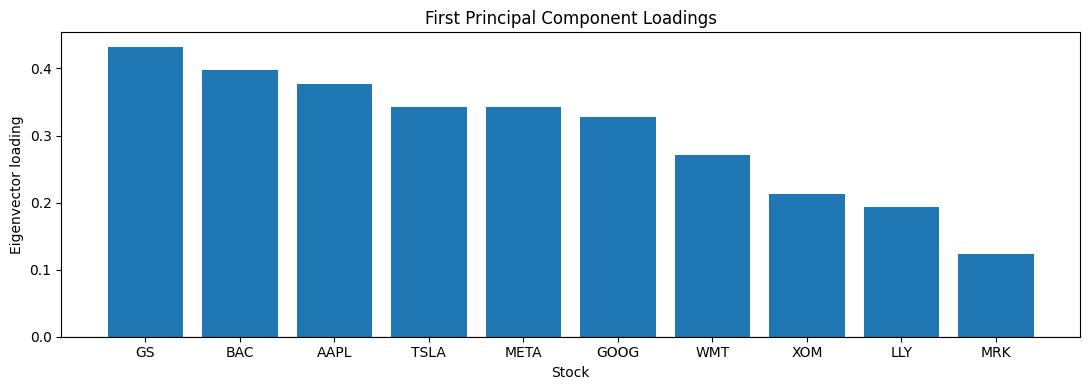

In [ ]:
Image.open('pic1.png')

* Five stocks; GS, BAC, AAPL, TSLA, and META account for 72.13% of PC1's total variance contribution: 18.68% + 15.78% + 14.19% + 11.78% + 11.71% = 72.13% . Especially Financial companies Goldman sachs(Gs) and Bank of America appear to be the top2 largest contributors of our first principal component, does it mean it is not a market factor but acts as one since GS and BAC might have investments in each of the other stocks in our portfolio creating this halo like common correlation?
* The other stocks like  MRK, LLY, XOM have single digit, below 5% contribution each, so the contribution is almost entirely driven by finance-techishque companies.
* This pc1 is not representative of market factor or is it? does it atleast a representative of s&p 500?






## Compare PC1 with the S&P 500
let's see how the pc1 of s&p 500 compares against our little portfolio pc1.

**Correlation between our PC1 and S&P 500: 0.9144**

wow! that's a substantial correlation. Nice man, Our pc1 is indeed more similar to s&p 500 returns than not!!! the pc1 is a good enough representative of our common market factor.

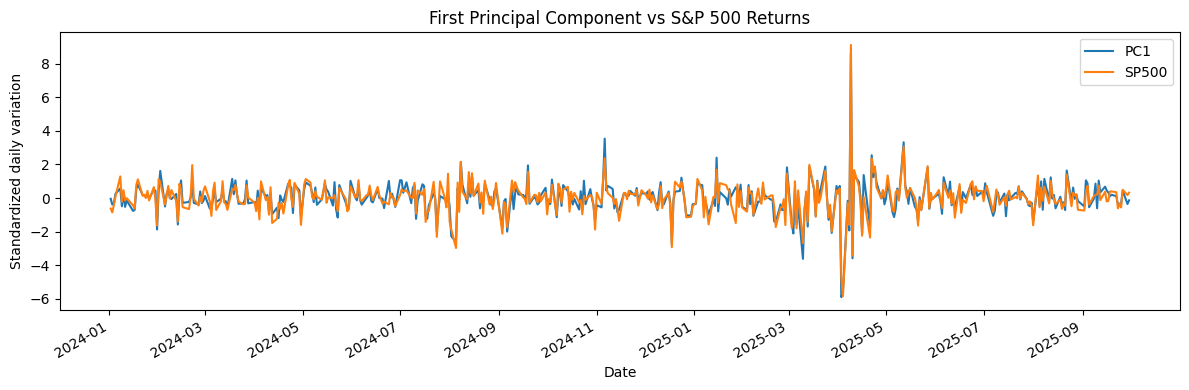

In [ ]:
Image.open('pic2.png')

## Which Stock's correlation change?

* Our previous table reported the average correlation, but that is insufficient to understand clustering, we want to which pair of stocks are strongly correlated after removing the first component; we want to inspect whether BAC–GS, LLY–MRK, and GOOG–META remain strongly related after removing the pc1.

* we have removed the effect of pc1 with denoising and detoning, so we'll compare the pair-wise correlation in each of these filtered and un-filtered versions of correlations.



| Pair | `Raw` | `Detoned` | `Denoised_Detoned` | `Change_after_Detoning` |
| --- | --- | --- | --- | --- |
| **BAC-GS** | 0.7779 | 0.4402 | -0.1342 | -0.3377 |
| **LLY-MRK** | 0.3218 | 0.2621 | -0.0488 | -0.0598 |
| **GOOG-META** | 0.4477 | 0.0845 | -0.1312 | -0.3632 |
| **AAPL-GOOG** | 0.4562 | 0.0349 | -0.1336 | -0.4213 |
| **TSLA-META** | 0.3310 | -0.1448 | -0.1327 | -0.4758 |
| **WMT-XOM** | 0.0617 | -0.1808 | -0.0956 | -0.2425 |

After just detoning we see the correlation between some assets still maintaining positive numbers but when denoised and detoned relationship between different assets in our portfolio became completely negative as if one would help hedge the other? But will it work in portfolio of any size or in any periods, our portfolio had only 10 assets in them

Compare original and transformed correlation structures;  how Raw correlation matrix,denoised correlation matrix and Denoised $\to$ Detoned correlation matrices look in heatmap.



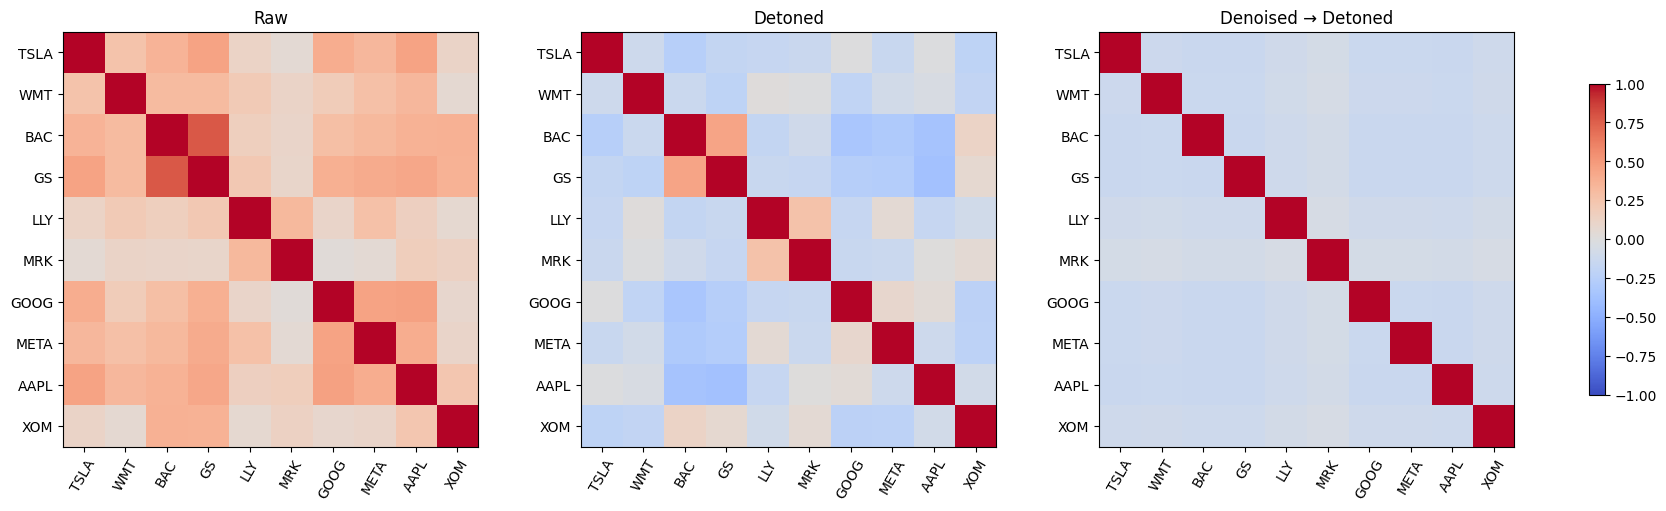

In [ ]:
Image.open('pic3.png')

They behave like completely different opposing entities after denoising and detoned; Correlation is all greyed-out between assets in our portfolio.

## Compare hierarchical clustering:

We can now do the HRP dendrogram for each version of our correlation matrices.



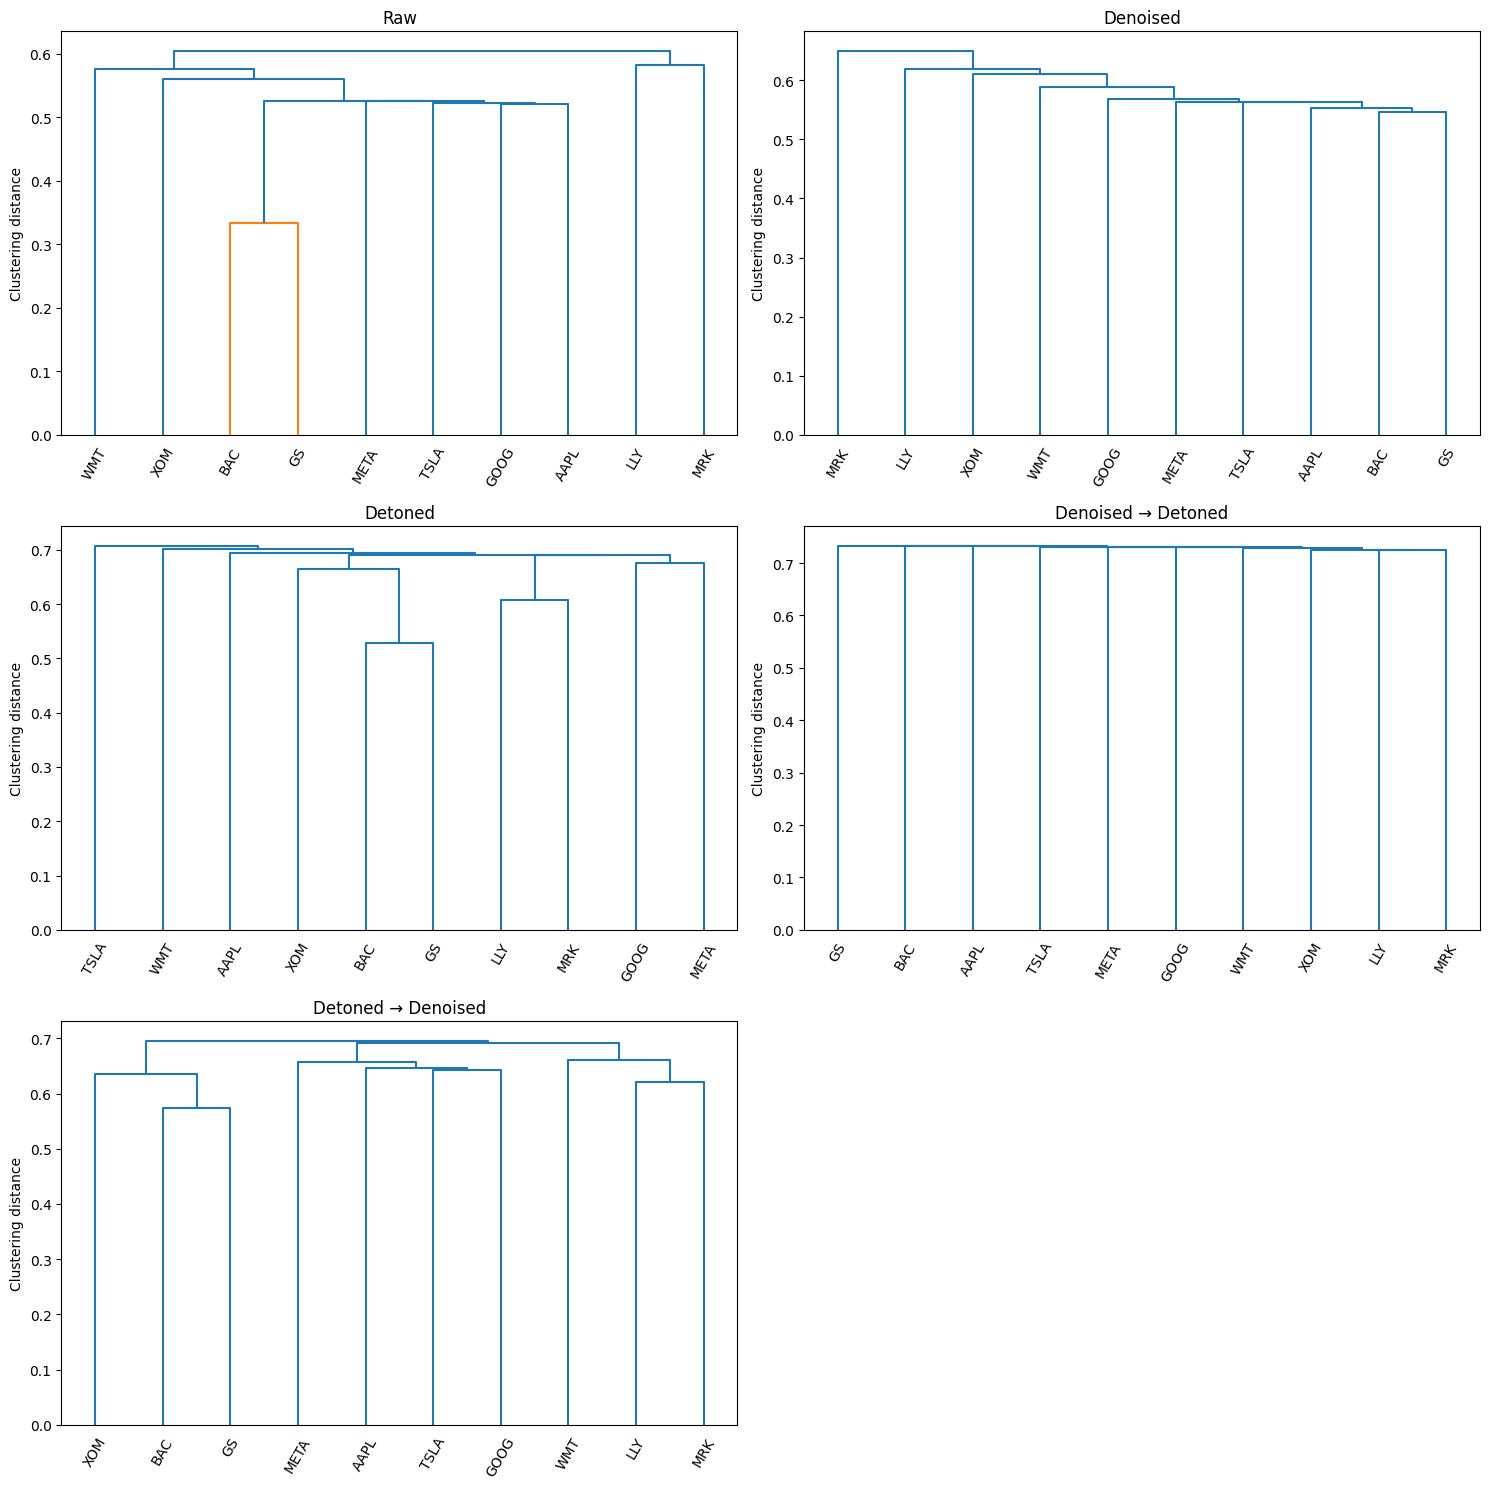

In [ ]:
Image.open('pic4.png')

* In the raw correlation matrix, BAC and GS are lying close to each other. Almost every other stock; META, TSLA, GOOG, AAPL,  merges sequentially into that same cluster around 0.52–0.56.But at least here we see some clustering patterns like Healthcare; LLY and MRK,  emerge as a distinct, tight cluster at 0.58.
* In (only detoned), Financials; BAC and GS,  form the tightest cluster at 0.53, LLY and MRK were pushed to the far right edge and only joined at the very top at 0.61, Mega-Cap Tech; GOOG and META,  form their own separate pair at 0.68.
* Pure Denoised doesn't seem to form a good enough cluster. It looks like a stair case almost engulfing all assets under one big cluster.
* Surprisingly, Our  denoised and detoned matrix creates the useless cluster, stacking all assets at the same level like freaky comb bristles.
* Detoned and denoised show better clustering pattern than denoised and detoned (I never expected that I thought detoned and denoised was the best until I see these clustering pictures), but in my opinion pure Detoned show better clustering like it didn't join walmart with healthcare candidates or XOM with Financial candidates, and the lesson notes also warned about not applying denoise after detoning because it may clip the remaining eigen values after the market factor or first principal component is removed which may have removed the correct ability to cluster properly.  

## What are our HRP weights?

| Allocation Method | TSLA | WMT | BAC | GS | LLY | MRK | GOOG | META | AAPL | XOM |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| **Raw HRP** | 2.27 | 20.00 | 8.98 | 4.95 | 6.15 | 12.41 | 10.76 | 2.94 | 12.33 | 19.21 |
| **Denoised HRP** | 1.89 | 16.50 | 8.10 | 6.18 | 8.30 | 16.78 | 8.48 | 5.71 | 8.56 | 19.49 |
| **Detoned HRP** | 2.39 | 20.00 | 9.90 | 10.32 | 6.67 | 14.95 | 7.61 | 4.84 | 10.23 | 13.09 |
| **Denoised → Detoned → HRP** | 1.19 | 19.32 | 10.26 | 7.83 | 6.78 | 13.71 | 9.93 | 3.58 | 7.60 | 19.82 |
| **Detoned → Denoised → HRP** | 2.28 | 20.00 | 12.33 | 8.03 | 6.94 | 13.91 | 10.49 | 3.66 | 6.03 | 16.33 |





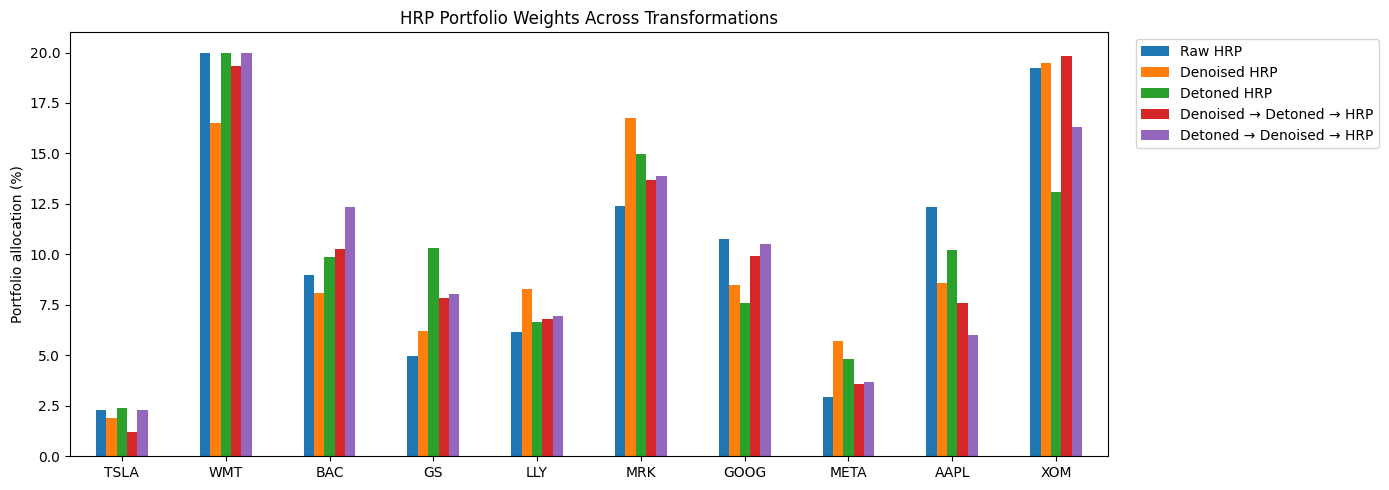

In [ ]:
Image.open('pic5.png')

HRP across all those different transformations of our correlation matrices, allocates 48% to 53% of capital in low-volatility groceries, healthcare, and energy like WMT, MRK, and XOM, but  limits the allocation to high volatile stocks like  TSLA  where it was 1.19%–2.39%, and META: 2.94%–5.71%. WMT repeatedly hits the 20% maximum position cap, displaying the necessity of our cap_simplex function to prevent single-stock concentration. The most important thing to note here is Detoned HRP produces more balanced sector diversification than Raw HRP: isolating Financials into a clean cluster lifts GS from 4.95% to 10.32% and BAC from 8.98% to 9.90%, while trimming XOM from 19.21% to 13.09%. And Denoised $\rightarrow $ Detoned $ \rightarrow $ HRP reverts closely to raw inverse-variance weights 19.32% WMT, 19.82% XOM because its flattened piano-keys resembling dendrogram lacks meaningful cluster splits I guess.


# Step 6: Out-of-Sample Performance check

set the raw correlation matrix as our baseline and compare every other variants with it to see how much they deviate from it, how much volatility each variant produced, how diversified the variant is, and the largest weight it gave to any of the assets in our portfolio.

| Method | `Weight_Change_vs_Raw` | `Annualized_Volatility` | `Effective_Assets(diversification metric)` | `Largest_Weight` |
| --- | --- | --- | --- | --- |
| **Raw HRP** | 0.0000 | 0.1525 | 7.4207 | 0.2000 |
| **Denoised HRP** | 0.1080 | 0.1513 | 7.7647 | 0.1949 |
| **Detoned HRP** | 0.1138 | 0.1574 | 8.0941 | 0.2000 |
| **Denoised → Detoned → HRP** | 0.0733 | 0.1497 | 7.4800 | 0.1982 |
| **Detoned → Denoised → HRP** | 0.0945 | 0.1531 | 7.7532 | 0.2000 |


Detoned HRP offers the highest diversification with effective_assets value being 8.0941(the closer it is to 10, because we have 10 assets, the more diversified our portfolio is), and its portfolio is also having high volatility compared to the baseline perhaps it is due to it trying to move from allocating more capital on low beta defensive stocks such as XOM to spreading it to high beta financial and market moving investment bank stocks; XOM drops from 19.21% to 13.09%, GS rises to 10.32%. And the volatility increase is also very modest like 0.49% for a better diversification. Weight_change_vs_RAW on detoned has 11.38% away from Raw, so removing the PC1 had given some boost in terms of hierarchical clustering and better portfolio allocation. I choose to talk only about detoned here because I find the other variants not very interesting based on effective_assets measure here and also factoring in the fact that pure Detoned provided better hierarchical clustering than others.



we are going to test all of our five combinations: raw, denoised HRP, detoned HRP, denoised -> detoned -> HRP, detoned -> denoised -> HRP and report which of them best performed in out-of-sample data.

I'll also compare these against the traditional Kelly portfolio from Step 1, once my teammate Duy's final weights are available.

let's prepare the out-of-sample returns first to fist.

**Out-of-sample observations:** 64

**Testing period:** 2025-10-01 00:00:00 to 2025-12-31 00:00:00

**Number of assets:** 10

| Date / Ticker | TSLA | WMT | BAC | GS | LLY | MRK | GOOG | META | AAPL | XOM |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| **2025-10-01** | 0.033144 | -0.010673 | -0.017639 | -0.013612 | 0.081809 | 0.073871 | 0.008171 | -0.023203 | 0.003220 | -0.006741 |
| **2025-10-02** | -0.051060 | -0.002550 | -0.003946 | -0.007804 | -0.006748 | -0.006879 | 0.003625 | 0.013536 | 0.006577 | -0.006251 |
| **2025-10-03** | -0.014151 | 0.003638 | 0.003170 | 0.013601 | 0.024419 | -0.003575 | 0.000081 | -0.022681 | 0.003461 | 0.017702 |
| **2025-10-06** | 0.054487 | 0.006172 | -0.004937 | 0.008608 | 0.006168 | -0.004373 | 0.020532 | 0.007177 | -0.005155 | 0.008299 |
| **2025-10-07** | -0.044479 | 0.005258 | -0.001984 | -0.008949 | -0.001680 | -0.013401 | -0.017415 | -0.003605 | -0.000818 | 0.000525 |


I'm not going to use these out-of-sample returns to calculate covariance matrix or determine clusters, optimize weights, or select the best strategy for evaluation like with our training data.

some prior assumptions(which later will be tweaked and adjusted reflecting reality closely):

1. Daily rebalancing to fixed target weights.
2. zero transcation costs.
3. a zero risk-free rate
4. All strategies treated alike (I have some extra trust on detoned though).



## calculate portfolio returns for different strategies:
* we already have weights_table from Step 5, containing one row of asset weights for each HRP strategy.
* We need to make sure three things the weights of all assets must sum to 1, the weights of all assets must not be greater than or equal to 0, weights of any asset must not exceed the 20% threshold.

| Date | Raw HRP | Denoised HRP | Detoned HRP | Denoised → Detoned → HRP | Detoned → Denoised → HRP |
| --- | --- | --- | --- | --- | --- |
| **2025-10-01** | 0.009853 | 0.014108 | 0.010953 | 0.010017 | 0.010403 |
| **2025-10-02** | -0.003279 | -0.003479 | -0.003621 | -0.003410 | -0.003964 |
| **2025-10-03** | 0.005591 | 0.005316 | 0.004780 | 0.006060 | 0.005362 |
| **2025-10-06** | 0.005670 | 0.005289 | 0.005166 | 0.005374 | 0.005843 |
| **2025-10-07** | -0.004324 | -0.004727 | -0.004763 | -0.004183 | -0.004831 |

This is the daily-return time series per correlation variant.

Now I have look at Duy's kelly portfolio and take the weight vector he'd calculated.

he has got this:

| Ticker | `Uncon_Quad` | `Uncon_Box` | `LO_Uncon_NoLev` | `Cap20_NoLev` | `Cap20_Lev` |
| --- | --- | --- | --- | --- | --- |
| **TSLA** | -0.135 | -0.111 | 0.205 | 0.2 | 0.2 |
| **WMT** | 7.033 | 6.251 | 0.000 | 0.2 | 0.2 |
| **BAC** | -2.455 | -2.000 | 0.000 | 0.0 | 0.2 |
| **GS** | 4.777 | 4.033 | 0.332 | 0.2 | 0.2 |
| **LLY** | 0.540 | 0.130 | 0.000 | 0.0 | 0.2 |
| **MRK** | -3.472 | -2.000 | 0.000 | 0.0 | 0.0 |
| **GOOG** | 1.782 | 1.924 | 0.000 | 0.2 | 0.2 |
| **META** | 1.109 | 1.343 | 0.463 | 0.2 | 0.2 |
| **AAPL** | -2.027 | -1.859 | 0.000 | 0.0 | 0.2 |
| **XOM** | 0.007 | 0.195 | 0.000 | 0.0 | 0.2 |

we have to take constrained below 20% weights which is the third column here and to be frank I don't like the lengthy name he chose for that so I'm going to shorten it to 'weights'

| Ticker | `weights` |
| --- | --- |
| **TSLA** | 0.2 |
| **WMT** | 0.2 |
| **BAC** | 0.0 |
| **GS** | 0.2 |
| **LLY** | 0.0 |
| **MRK** | 0.0 |
| **GOOG** | 0.2 |
| **META** | 0.2 |
| **AAPL** | 0.0 |
| **XOM** | 0.0 |

After including this kelly weights our portfolio returns matrix will become:

| Date | Raw HRP | Denoised HRP | Detoned HRP | Denoised → Detoned → HRP | Detoned → Denoised → HRP | Traditional Kelly |
| --- | --- | --- | --- | --- | --- | --- |
| **2025-10-01** | 0.009853 | 0.014108 | 0.010953 | 0.010017 | 0.010403 | -0.001235 |
| **2025-10-02** | -0.003279 | -0.003479 | -0.003621 | -0.003410 | -0.003964 | -0.008851 |
| **2025-10-03** | 0.005591 | 0.005316 | 0.004780 | 0.006060 | 0.005362 | -0.003902 |
| **2025-10-06** | 0.005670 | 0.005289 | 0.005166 | 0.005374 | 0.005843 | 0.019395 |
| **2025-10-07** | -0.004324 | -0.004727 | -0.004763 | -0.004183 | -0.004831 | -0.013838 |

## How will we check which allocation performs better in out-of-sample data?

we will specifically use 6 metrics they are:
* cumulative returns $ \prod_{t=1}^T(1+R_{p,t})-1 $, the higher it is the better our portfolio weights are.
* sharpe ratio: $ \sqrt{252}\,\bar R_p/s_p $ this is annualized sharpe ratio, the higher sharpe indicates better portfolio.
* Annualized volatility: $ \sqrt{252}\,s_p $ the lower the beter.
* Maximum drawdown: $ \min_t(V_t/\max_{s\leq t}V_s-1)\ $ which is the largest fall from the sky (in terms of stock price climbing adventures ofcourse), the closer this value to zero less number of bones break.
* 95% cvar: $ -E[R_p\mid R_p\leq q_{0.05}] $, lower the better. For our purpose, CVaR measures the average loss among the worst 5% of observed daily returns. It is a historical tail-loss estimate.
* sortino ratio: Annualized mean excess return / downside deviation, it needs to be higher.


| Method | `Cumulative_Return` | `Sharpe_Ratio` | `Annualized_Volatility` | `Maximum_Drawdown` | `CVaR_95` | `Sortino_Ratio` |
| --- | --- | --- | --- | --- | --- | --- |
| **Raw HRP** | 13.4903 | 4.6859 | 10.7656 | -3.1250 | 1.2757 | 8.1917 |
| **Denoised HRP** | 14.0046 | 4.6953 | 11.1326 | -3.0022 | 1.2669 | 8.3961 |
| **Detoned HRP** | 13.3143 | 4.4613 | 11.1805 | -3.0443 | 1.2691 | 7.9266 |
| **Denoised → Detoned → HRP** | 13.7877 | 4.7499 | 10.8398 | -3.0056 | 1.2707 | 8.3021 |
| **Detoned → Denoised → HRP** | 13.9622 | 4.6741 | 11.1522 | -3.0535 | 1.2938 | 8.2199 |
| **Traditional Kelly** | 7.8828 | 1.6508 | 19.2078 | -6.5192 | 2.4688 | 2.5184 |

All five HRP versions show better sharpe_ratio, sortino_ratio, volatility, drawdown, cvar_95 than classic kelly, in fact they substantially outperform it. Among the HRP variants, Denoised achieved the highest cumulative return of 14% and Denoised $\to $ Detoned achieved the highest sharpe ratio and standalone Denoised HRP achieved the highest sortino. The most surprising thing to me to note is the pure standalone Detoned HRP gave a better diversification structure but when tested with this out-of-sample data, it performed poorly among HRP mutations that even Raw HRP won over it (save maximum drawdown and cvar).

## single vs mob who wins?

We now need to see if combining methods offer any meaningful improvement over individual methods like Raw HRP as the clustering baseline, and Denoised HRP and Detoned HRP as single-improvement comparisons.

what i'm going to do:

1. first i'll keeep the raw HRP as our baseline to see how other mutations of HRP such as denoised and so on and our traditional kelly vary from it.
2. And then we have to subtract the Raw HRP's metrics from every other mutation's metrics. The metrics are; Cumulative Return, Annualized Volatility, Maximum Drawdown, and CVaR (95%). This way we will know whether cleaning correlation increased return or reduced volatility or decreased max drawdown or whatever.
3. Subtract Raw HRP's Sharpe Ratio and Sortino Ratio from each strategy's.

| Method | `Cumulative_Return_Delta_pp` | `Annualized_Volatility_Delta_pp` | `Maximum_Drawdown_Delta_pp` | `CVaR_95_Delta_pp` | `Sharpe_Ratio_Delta` | `Sortino_Ratio_Delta` |
| --- | --- | --- | --- | --- | --- | --- |
| **Raw HRP** | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| **Denoised HRP** | 0.5144 | 0.3670 | 0.1228 | -0.0089 | 0.0093 | 0.2045 |
| **Detoned HRP** | -0.1760 | 0.4148 | 0.0807 | -0.0066 | -0.2247 | -0.2651 |
| **Denoised → Detoned → HRP** | 0.2974 | 0.0742 | 0.1194 | -0.0050 | 0.0639 | 0.1105 |
| **Detoned → Denoised → HRP** | 0.4720 | 0.3865 | 0.0715 | 0.0180 | -0.0119 | 0.0282 |
| **Traditional Kelly** | -5.6074 | 8.4422 | -3.3942 | 1.1931 | -3.0351 | -5.6733 |

Denoise gives the largest cumulative gain at 0.5144% compared to the baseline and this is no surprise. This Denoising has another standard name called Marchenko-pastur denoising. Its sortino improvement is also higher than others at 0.2045. I was first thinking denoised $\to$ detoned will be the ultimate winner when I began this task and then after observing standalone detone's ability to diversify correctly I was rooting for it until the previous result where we clearly see Denoise snatching the hall of fame but still  Denoised → Detoned → HRP secured the strongest Sharpe ratio gain +0.0639 with least added volatility among others at 0.0742%. Our Traditional kelly is the clown here losing in all of the metrics compared against others.

## Denoising vs Detoning vs Raw vs detoning+denoising vs denosing+detoning, who wins against who?

RaW HRP is our baseline as before and now we have to perform pairwise ablation test across all our 6 combinations (2 Combined * 3 Single) like we are going to pit each sequential pipeline Denoised → Detoned  and Detoned → Denoised  directly against each standalone baseline Raw , Denoised, and Detoned. We want to know whether adding detoning on top of denoising beat standalone Denoised HRP or viceversa.



| Index | `Combined` | `Compared_With` | `Return_Delta_pp` | `Sharpe_Delta` | `Volatility_Delta_pp` | `MaxDD_Improvement_pp` | `CVaR_Improvement_pp` |
| --- | --- | --- | --- | --- | --- | --- | --- |
| **0** | Denoised → Detoned → HRP | Raw HRP | 0.2974 | 0.0639 | 0.0742 | 0.1194 | 0.0050 |
| **1** | Denoised → Detoned → HRP | Denoised HRP | -0.2169 | 0.0546 | -0.2928 | -0.0034 | -0.0039 |
| **2** | Denoised → Detoned → HRP | Detoned HRP | 0.4734 | 0.2886 | -0.3406 | 0.0387 | -0.0016 |
| **3** | Detoned → Denoised → HRP | Raw HRP | 0.4720 | -0.0119 | 0.3865 | 0.0715 | -0.0180 |
| **4** | Detoned → Denoised → HRP | Denoised HRP | -0.0424 | -0.0212 | 0.0196 | -0.0513 | -0.0269 |
| **5** | Detoned → Denoised → HRP | Detoned HRP | 0.6480 | 0.2128 | -0.0283 | -0.0092 | -0.0246 |

Here postive returns_delta, sharpe_delta, max drawdown and Cvar are all good and negative volatility is good and in favour of the combination being concerned.

The actual result is chaining denoising and detoning doesn't always perform better than standalone Denoised HRP, but it beats both Raw HRP and Detoned HRP. When Denoised + Detoned is compared with Raw HRP it produced 0.2974 Return differnce and 0.06 Sharpe difference, however when compare that with standalone denoise HRP it gave a negative return difference meaning denoise outperforms it and tail metrics such as max drawdown and cvar also went negative zone, but negative volatility is appreciable. If we reverse this; Detoned $\to$ Denoised then pure standalone Denoised completely smashes it in all metrics. perhaps the denoising after detoning makes the model not perform well with this out of sample data. Denoised $\to $ Detoned seems pretty good against standalone Detoned; better returns, better sharpe, better negative volatility, better drawdown except the slight drop in CVAR.


## plotting these demons

plot out of sample cumulative returns and drawdowns.

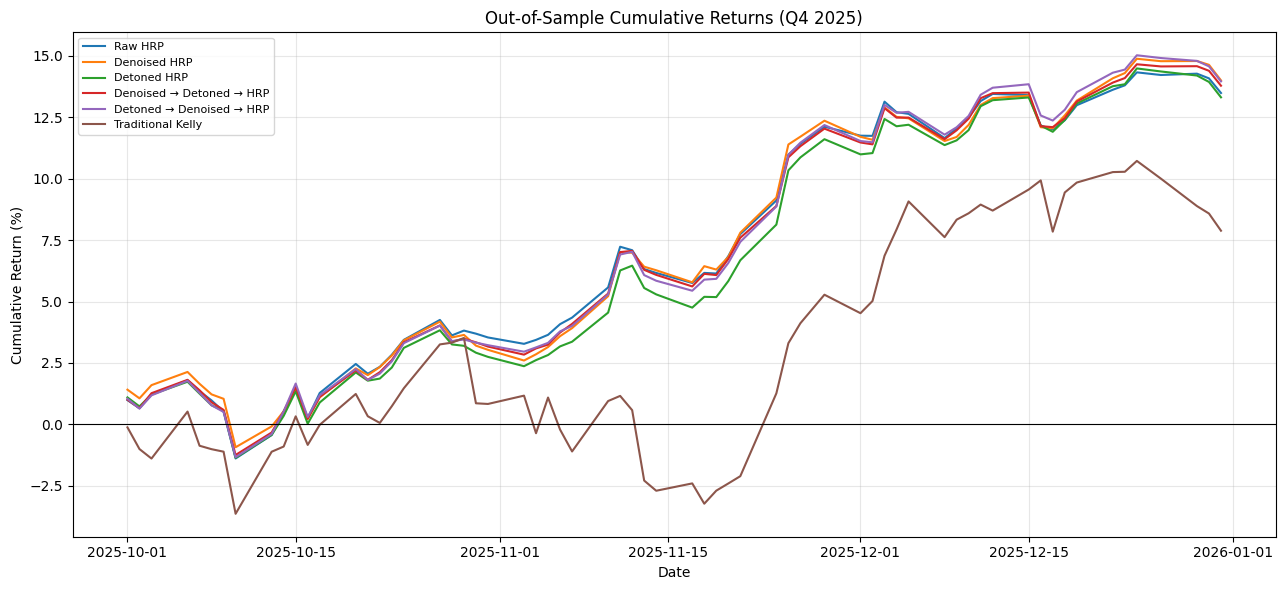

In [4]:

Image.open('pic6.png')

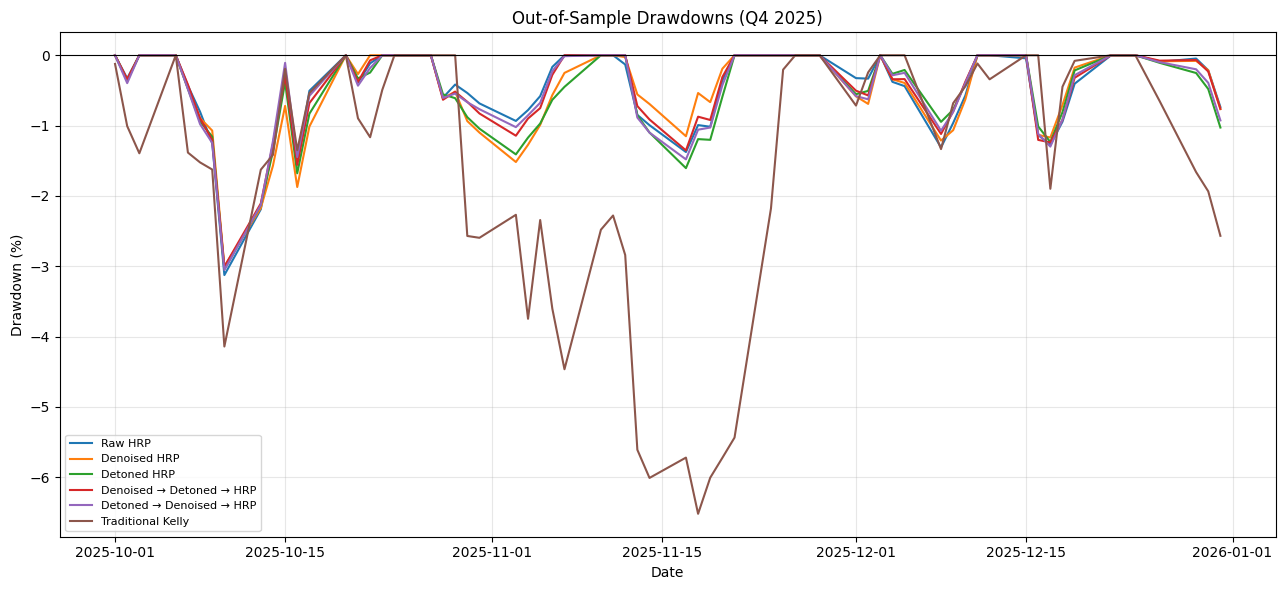

In [5]:
Image.open('pic7.png')

for cumulative returns all five HRP mutations seem to synchronize or move tightly together compounding to around 14-ish % .

peak-to-trough drawdowns strictly contained above -3.13% (with Denoised HRP leading the pack at the upper edge of the return envelope). Around November month traditional kelly suffered the heaviest blow of the drawdown limping at about -6.5% and giving only 7-ish % of returns. So, HRP diversification really seem to protect the portfolio from severe drawdowns that kelly doesn't dodge as well.

## Asset level contribution calculation:

we want to which asset Google or meta or walmart or exxon mobile or whatever contributed how much to our differences in average daily performance.

goal
We want to know which stocks actually had a positive cumulative returns in the test period and which dragged the returns down, and rank them sort them from best to worst.



**Individual asset cumulative returns (%):**

| Ticker | `Cumulative_Return_%` |
| --- | --- |
| **LLY** | 40.849 |
| **GOOG** | 28.844 |
| **MRK** | 25.414 |
| **GS** | 10.379 |
| **WMT** | 8.102 |
| **AAPL** | 6.767 |
| **XOM** | 6.732 |
| **BAC** | 6.610 |
| **TSLA** | 1.124 |
| **META** | -10.116 |

Wow in this particular test period: 2025-10-31 to 2025-12-31, LLY gave the highest cumulative return of all and Meta for some reason nosedived to warzone(negative region)



now we want to calculate the total contribution per strategy; we would multiply each strategy's weight vector with each stock's summed daily returns to see how many percentage points each individual stock added to or subtracted from each portfolio's total return.

**Asset contributions to summed daily returns** *(percentage points; NOT compounded attribution)*

| Method | TSLA | WMT | BAC | GS | LLY | MRK | GOOG | META | AAPL | XOM |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| **Raw HRP** | 0.0886 | 1.6925 | 0.6217 | 0.5276 | 2.1802 | 2.9497 | 2.8450 | -0.2712 | 0.8543 | 1.3234 |
| **Denoised HRP** | 0.0740 | 1.3967 | 0.5607 | 0.6594 | 2.9424 | 3.9888 | 2.2429 | -0.5257 | 0.5933 | 1.3427 |
| **Detoned HRP** | 0.0935 | 1.6925 | 0.6851 | 1.1008 | 2.3650 | 3.5544 | 2.0124 | -0.4460 | 0.7084 | 0.9017 |
| **Denoised → Detoned → HRP** | 0.0463 | 1.6346 | 0.7101 | 0.8351 | 2.4038 | 3.2587 | 2.6249 | -0.3293 | 0.5264 | 1.3656 |
| **Detoned → Denoised → HRP** | 0.0892 | 1.6925 | 0.8539 | 0.8565 | 2.4594 | 3.3065 | 2.7748 | -0.3369 | 0.4176 | 1.1248 |

Pharmaceutical companies (MRK and LLY) and Walmart (WMT) pumped up the vast majority of out-of-sample gains, and META was the single negative contributor across all HRP variants ranging between -0.27 to -0.53.

lets see which variant gave the highest returns as well:

I'm going to sum up the returns for variant for all assets

| Method | `Total Contribution` |
| --- | --- |
| **Denoised HRP** | 13.2750 |
| **Detoned → Denoised → HRP** | 13.2383 |
| **Denoised → Detoned → HRP** | 13.0762 |
| **Raw HRP** | 12.8120 |
| **Detoned HRP** | 12.6677 |


Also here Denoised HRP seems to give the highest integrated returns of 13.2750 and the least came from Detoned HRP, surprisingly Detoned $\to $ Denoised falls short only by few decimals. Nice!



 Now we want to which specific overweight or underweight bets caused a strategy to beat or lose to Raw HRP?; we will Subtract Raw HRP's weights from every other strategy's weights and multiplies by the stock returns.

 Comparing the differences relative to Raw HRP we get:




| Method | TSLA | WMT | BAC | GS | LLY | MRK | GOOG | META | AAPL | XOM |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| **Raw HRP** | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | -0.0000 | 0.0000 | 0.0000 |
| **Denoised HRP** | -0.0147 | -0.2958 | -0.0610 | 0.1318 | 0.7622 | 1.0390 | -0.6021 | -0.2545 | -0.2610 | 0.0192 |
| **Detoned HRP** | 0.0048 | 0.0000 | 0.0634 | 0.5731 | 0.1848 | 0.6047 | -0.8326 | -0.1748 | -0.1459 | -0.4217 |
| **Denoised → Detoned → HRP** | -0.0423 | -0.0579 | 0.0883 | 0.3074 | 0.2236 | 0.3090 | -0.2201 | -0.0581 | -0.3279 | 0.0422 |
| **Detoned → Denoised → HRP** | 0.0006 | 0.0000 | 0.2321 | 0.3288 | 0.2792 | 0.3568 | -0.0701 | -0.0656 | -0.4367 | -0.1986 |

and summing up;

| Method | `difference` |
| --- | --- |
| **Denoised HRP** | 0.4630 |
| **Detoned → Denoised → HRP** | 0.4264 |
| **Denoised → Detoned → HRP** | 0.2643 |
| **Raw HRP** | 0.0000 |
| **Detoned HRP** | -0.1442 |

Our superstar is Denoised HRP here out-performed,out-throned Raw HRP by 0.4630 pp thanks to its aggressive investment towards pharma companies that drags from Google, Meta, Apple, Tesla, Walmart, Bank of America didn't that humph to pull it down.

The only disappointing thing to note here is Detoned HRP trailing behind Raw Correlation HRP shattering my faith, I thought it would be the ultimate winner once upon a time.(just a jest, no faith on anything)

## Does our Complexity pay off?

Now I want to create a Unified decision table to see each of our different versions of correlation matrices and see how they do diversification and get out of sample returns and risks.

plan:

1. I'm going to treat Raw correlation as the baseline and create an empty table indexxed by every strategy name.
2. And then show how much trading or turnover each method requires to implement.
3. Compute the effective number of bets $ \frac{1}{ sum(w^2) } $ and the single largest stock weight (max(w) * 100) to capture how evenly capital is spread across the 10 assets.
4. Pull Out-of-Sample Performance Metrics:  Cumulative Return (%), Sharpe Ratio, and 95% CVaR (%)
* I may not be accurate in executing the steps as I define them here but the end goal won't be missed.



| Method | `Reallocation_vs_Raw_%` | `Effective_Assets` | `Largest_Weight_%` | `Cumulative_Return_%` | `Sharpe_Ratio` | `CVaR_95_%` |
| --- | --- | --- | --- | --- | --- | --- |
| **Raw HRP** | 0.0000 | 7.4207 | 20.0000 | 13.4903 | 4.6859 | 1.2757 |
| **Denoised HRP** | 10.7974 | 7.7647 | 19.4914 | 14.0046 | 4.6953 | 1.2669 |
| **Detoned HRP** | 11.3759 | 8.0941 | 20.0000 | 13.3143 | 4.4613 | 1.2691 |
| **Denoised → Detoned → HRP** | 7.3320 | 7.4800 | 19.8244 | 13.7877 | 4.7499 | 1.2707 |
| **Detoned → Denoised → HRP** | 9.4523 | 7.7532 | 20.0000 | 13.9622 | 4.6741 | 1.2938 |

Our current superstar Denoised HRP reallocates 10.78% of capital compared to Raw HRP to achieve highest cumulative return of 14%, lowest 95% CVar, lowest single asset investment percentage of 19.49%, and improved diversification with effective assets of 7.76(do we have to be super diversified though?), but Denoised $\to $ Detoned achieves the highest sharpe ratio (close to 4.75), and the worst performer award goes to Detoned.

## What does this 10.78% Reallocation Vs Raw mean?

 Suppose we already hold the Raw HRP portfolio on Day 1, and one fine day we decide to switch to Denoised HRP to get that tiny bit higher returns. To change our holdings from Raw HRP to Denoised HRP, we would sell 3.77% of your existing AAPL shares (bringing AAPL down from 12.33% to 8.56%) and use that cash to buy 4.37% more MRK shares bringing MRK up from 12.41% to 16.78%.

 The complete table for switching is presented here:
 ### Exact Trade Breakdown (Denoised HRP vs. Raw HRP)

| Action | Ticker | Raw HRP (%) | Denoised HRP (%) | Weight Change (pp) |
| :--- | :--- | :---: | :---: | :---: |
| Buy (Overweight) | **MRK** | 12.41% | 16.78% | **+4.37 pp** |
| Buy (Overweight) | **META** | 2.94% | 5.71% | **+2.77 pp** |
| Buy (Overweight) | **LLY** | 6.15% | 8.30% | **+2.15 pp** |
| Buy (Overweight) | **GS** | 4.95% | 6.18% | **+1.23 pp** |
| Buy (Overweight) | **XOM** | 19.21% | 19.49% | **+0.28 pp** |
| **Total Buys** | — | — | — | **+10.80 pp** |
| Sell (Underweight) | **AAPL** | 12.33% | 8.56% | **-3.77 pp** |
| Sell (Underweight) | **WMT** | 20.00% | 16.50% | **-3.50 pp** |
| Sell (Underweight) | **GOOG** | 10.76% | 8.48% | **-2.28 pp** |
| Sell (Underweight) | **BAC** | 8.98% | 8.10% | **-0.88 pp** |
| Sell (Underweight) | **TSLA** | 2.27% | 1.89% | **-0.38 pp** |
| **Total Sells** | — | — | — | **-10.80 pp**  |

## Can our Denoise survive the transaction costs and triumph as the winner or the rivals snatch the throne from it?

| Strategy | `0 bps` | `5 bps` | `10 bps` | `20 bps` |
| --- | --- | --- | --- | --- |
| **Denoised HRP** | 14.0046 | 13.9862 | 13.9677 | 13.9308 |
| **Denoised → Detoned → HRP** | 13.7877 | 13.7697 | 13.7516 | 13.7156 |
| **Detoned HRP** | 13.3143 | 13.2959 | 13.2775 | 13.2407 |
| **Detoned → Denoised → HRP** | 13.9622 | 13.9437 | 13.9252 | 13.8883 |
| **Raw HRP** | 13.4903 | 13.4723 | 13.4543 | 13.4184 |


| Strategy | `Total_Q4_Turnover` |
| --- | --- |
| **Denoised HRP** | 0.3240 |
| **Denoised → Detoned → HRP** | 0.3169 |
| **Detoned HRP** | 0.3246 |
| **Detoned → Denoised → HRP** | 0.3246 |
| **Raw HRP** | 0.3168 |


Yes, Denoised HRP easily survives transaction costs and stays number 1 across every single transaction fee tier (0, 5, 10, and 20 bps), at 5 bps it was leading, at 10 it was, at 15 it did, even under the steepest 20 bps one-way transaction cost, Denoised HRP only loses 0.074 percentage points of return 14.0046% down to 13.931%, preserving almost its entire lead over Raw HRP (13.4184%).

Denoise is our winner!

